# Model selection: which decision tree do we use?
*Taiwanese bankruptcy prediction, Augmented Decision final project*

**Goal.** Choose the final model, compare it with baselines and test it once.

**The decision we support** (Lecture 1; `bankruptcy_prediction.ipynb`, 1.2). An analyst flags a firm for review or not. A missed bankruptcy costs 10, a needless review costs 1:

| | Firm survives | Firm goes bankrupt |
|---|---|---|
| No flag | 0 | 10 |
| Flag | 1 | 0 |

Flagging has the lower expected loss when the firm's bankruptcy probability $p$ satisfies $1\cdot(1-p) \le 10\cdot p$, that is when $p \ge 1/11 \approx 0.091$. **So we flag every firm whose estimated probability is at least 0.091.**

**How we score a model.** The average cost per firm, $\frac{1 \cdot FP + 10 \cdot FN}{n}$ (FP = needless reviews, FN = missed bankruptcies). Lower is better.

**The plan.**
1. Try many candidate models with 5-fold cross-validation on the development data.
2. Pick the cheapest one.
3. Refit it and evaluate it **once** on the untouched test set.

## 1. Setup
Libraries and fixed settings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

C_FP, C_FN = 1, 10                     # needless review, missed bankruptcy
THRESHOLD = C_FP / (C_FP + C_FN)       # flag when P(bankrupt) >= 1/11
SEED = 42

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Data and the train/validation/test roles
We reuse the split and the five folds saved by `variable_selection.ipynb`, so that both notebooks work on exactly the same records (Lecture 2, p. 2):

| Part | Role | Size |
|---|---|---|
| Development data (80%) | split into 5 folds: train on 4, validate on the 5th, five times | 5,455 firms, 176 bankrupt |
| Test data (20%) | locked until the very end | 1,364 firms, 44 bankrupt |

In [2]:
data = pd.read_csv("data/data.csv")
data.columns = data.columns.str.strip()
split = pd.read_csv("outputs/variable_selection/split_assignments.csv")

X, y = data.drop(columns="Bankrupt?"), data["Bankrupt?"]
dev = split.loc[split["split"] == "development", "source_row_id"].to_numpy()
test = split.loc[split["split"] == "test", "source_row_id"].to_numpy()
fold = split.set_index("source_row_id").loc[dev, "cv_validation_fold"].astype(int).to_numpy()

X_dev, y_dev, X_test, y_test = X.loc[dev], y.loc[dev], X.loc[test], y.loc[test]
print(f"Development: {len(dev)} firms ({y_dev.sum()} bankrupt) | Test: {len(test)} firms ({y_test.sum()} bankrupt)")

Development: 5455 firms (176 bankrupt) | Test: 1364 firms (44 bankrupt)


## 3. Two helper functions
**`select_variables`** is the variable selection from `variable_selection.ipynb` (Lecture 4, L1 penalty), using the same settings:
1. drop constant columns and exact copies of another column;
2. standardise every column (mean 0, standard deviation 1), so that the penalty treats all ratios alike;
3. fit a logistic regression with an L1 penalty and keep the variables whose coefficient is not zero.

$C$ sets the penalty strength: **smaller $C$ = stronger penalty = fewer variables.** The function only learns from the rows it receives.

**`score`** turns probabilities into decisions (flag if $p \ge 0.091$) and returns the cost per firm, plus recall (share of bankruptcies caught) and the number of flags.

In [3]:
def select_variables(X_train, y_train, C):
    keep = []
    for name in X_train.columns:                              # 1. structural cleanup
        column = X_train[name]
        if column.nunique() > 1 and not any(column.equals(X_train[k]) for k in keep):
            keep.append(name)
    if C is None:                                             # "no selection"
        return keep
    Z = StandardScaler().fit_transform(X_train[keep])         # 2. standardise
    lasso = LogisticRegression(l1_ratio=1, C=C, solver="saga", tol=1e-4,
                               max_iter=20_000, random_state=SEED).fit(Z, y_train)
    return [name for name, b in zip(keep, lasso.coef_[0]) if abs(b) >= 1e-6]   # 3. non-zero


def score(y_true, p_bankrupt):
    flag = p_bankrupt >= THRESHOLD
    y_true = np.asarray(y_true)
    fp, fn = int((flag & (y_true == 0)).sum()), int((~flag & (y_true == 1)).sum())
    return {"cost": (C_FP * fp + C_FN * fn) / len(y_true),
            "recall": 1 - fn / y_true.sum(), "flags": int(flag.sum())}

## 4. The candidates
A decision tree asks a firm a sequence of yes/no questions. Each question is the split with the largest drop in **Gini impurity** (Trees lecture, p. 7). The firm ends in a **leaf**; the share of bankrupt training firms in that leaf is its estimated probability $p$.

We tune three settings:

| Setting | What it does | Values tried |
|---|---|---|
| Variable selection $C$ | how many ratios the tree may use | 0.01 (about 5 ratios), 0.1 (about 30), none (all 92) |
| `max_depth` | how many questions in a row | 2, 3, 4, 5 |
| `min_samples_leaf` | minimum number of firms in a leaf | 10, 25, 50, 100 |

That is $3 \times 4 \times 4 = 48$ candidates. Larger $C$ values (1 and 10) keep 70 to 90 of the 92 ratios in `variable_selection.ipynb`, so they hardly select anything; "none" covers that end.

**Why tune at all?** A tree that is too small cannot represent the pattern (*underfitting*). A tree that is too large memorises chance details of the training firms (*overfitting*) and does worse on new firms (Lecture 2, p. 4; Trees lecture, p. 9). Small leaves also give unstable probabilities: with 10 firms, one bankruptcy already gives $p = 0.1 \ge 0.091$.

## 5. Cross-validation
For each of the 5 folds, the next cell
1. selects the variables **on the 4 training folds only** (so the validation firms cannot influence the selection: no *data leakage*, as the brief requires);
2. trains every tree on those training firms;
3. scores it on the 5th fold.

Each candidate thus gets five validation costs. This takes about a minute.

In [4]:
OPTIONS = {"C = 0.01": 0.01, "C = 0.1": 0.1, "no selection": None}
rows = []
for k in range(1, 6):
    train, valid = fold != k, fold == k
    for option, C in OPTIONS.items():
        columns = select_variables(X_dev[train], y_dev[train], C)
        for depth in [2, 3, 4, 5]:
            for leaf in [10, 25, 50, 100]:
                tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
                tree.fit(X_dev.loc[train, columns], y_dev[train])
                p = tree.predict_proba(X_dev.loc[valid, columns])[:, 1]
                rows.append({"fold": k, "selection": option, "depth": depth, "leaf": leaf,
                             "variables": len(columns), **score(y_dev[valid], p)})

results = pd.DataFrame(rows)
summary = (results.groupby(["selection", "depth", "leaf"])
           .agg(mean_cost=("cost", "mean"), std_cost=("cost", "std"),
                recall=("recall", "mean"), variables=("variables", "mean"))
           .reset_index())
print(f"{len(results)} trees trained and scored")

240 trees trained and scored


## 6. Results of all candidates
Each cell is the mean validation cost per firm of one candidate. **Darker = cheaper.** For comparison, never flagging anyone costs about 0.32.

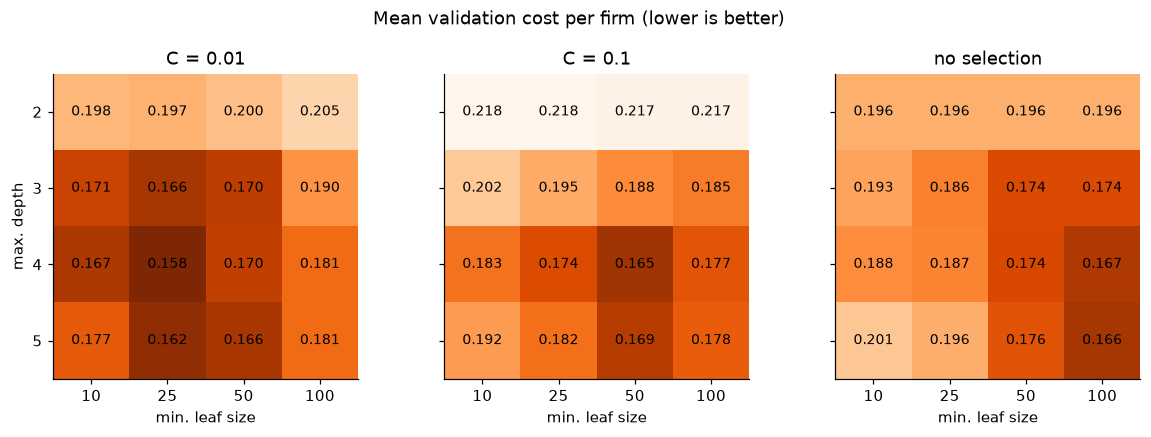

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, option in zip(axes, OPTIONS):
    grid = summary[summary["selection"] == option].pivot(index="depth", columns="leaf", values="mean_cost")
    ax.imshow(grid, cmap="Oranges_r", vmin=summary["mean_cost"].min(), vmax=summary["mean_cost"].max())
    for i, depth in enumerate(grid.index):
        for j, leaf in enumerate(grid.columns):
            ax.text(j, i, f"{grid.loc[depth, leaf]:.3f}", ha="center", va="center", fontsize=9)
    ax.set(title=option, xlabel="min. leaf size", xticks=range(4), xticklabels=grid.columns,
           yticks=range(4), yticklabels=grid.index)
axes[0].set_ylabel("max. depth")
fig.suptitle("Mean validation cost per firm (lower is better)", y=1.04)
plt.show()

**Reading the heatmap.**
- **Depth 2 is too simple** in every panel (about 0.20 to 0.22): underfitting.
- **Leaves of 10 firms** are usually worse than larger leaves: their probabilities are unstable.
- The cheapest region is **depth 3–5 with leaves of 25–50**, with the strongest selection ($C = 0.01$).

## 7. Choosing the model
**Rule, fixed in advance:** take the candidate with the lowest mean validation cost. The test set plays no role in this choice.

The table compares the winner with the best tree without selection and with the trivial baseline *never flag*.

In [6]:
best = summary.sort_values("mean_cost").iloc[0]
best_all = summary[summary["selection"] == "no selection"].sort_values("mean_cost").iloc[0]
never_flag = np.mean([score(y_dev[fold == k], np.zeros((fold == k).sum()))["cost"] for k in range(1, 6)])

comparison = pd.DataFrame([best, best_all], index=["chosen model", "best without selection"])
comparison.loc["never flag", ["mean_cost", "recall", "variables"]] = [never_flag, 0, 0]
comparison[["depth", "leaf"]] = comparison[["depth", "leaf"]].astype("Int64")
comparison.round(3)

,selection,depth,leaf,mean_cost,std_cost,recall,variables
chosen model,C = 0.01,4,25,0.158,0.014,0.693,5.4
best without selection,no selection,5,100,0.166,0.028,0.693,92.0
never flag,NaN,<NA>,<NA>,0.323,NaN,0.000,0.0


**Result.** The chosen model uses selection with $C = 0.01$, depth 4 and at least 25 firms per leaf.
- It **halves the cost** of never flagging (0.158 vs 0.323) and catches about 70% of the bankruptcies.
- It is slightly cheaper than the best tree on all 92 ratios (0.158 vs 0.166). But this difference is **smaller than the spread between folds** (`std_cost`), so we do not claim that selection improves prediction. Its real advantage: **about 5 ratios instead of 92** for the same performance, which makes the model easier to explain and to use.

## 8. The final tree
We freeze these settings and refit on all development firms: first the selection, then the tree. Refitting after validation is fine as long as the test set stays untouched (Lecture 2, p. 3).

In the plot, a firm answering *yes* goes left. `samples` is the share of firms reaching the box, `value` = [share not bankrupt, share bankrupt]. **Orange boxes have a bankrupt share of at least 0.091: their firms get flagged.**

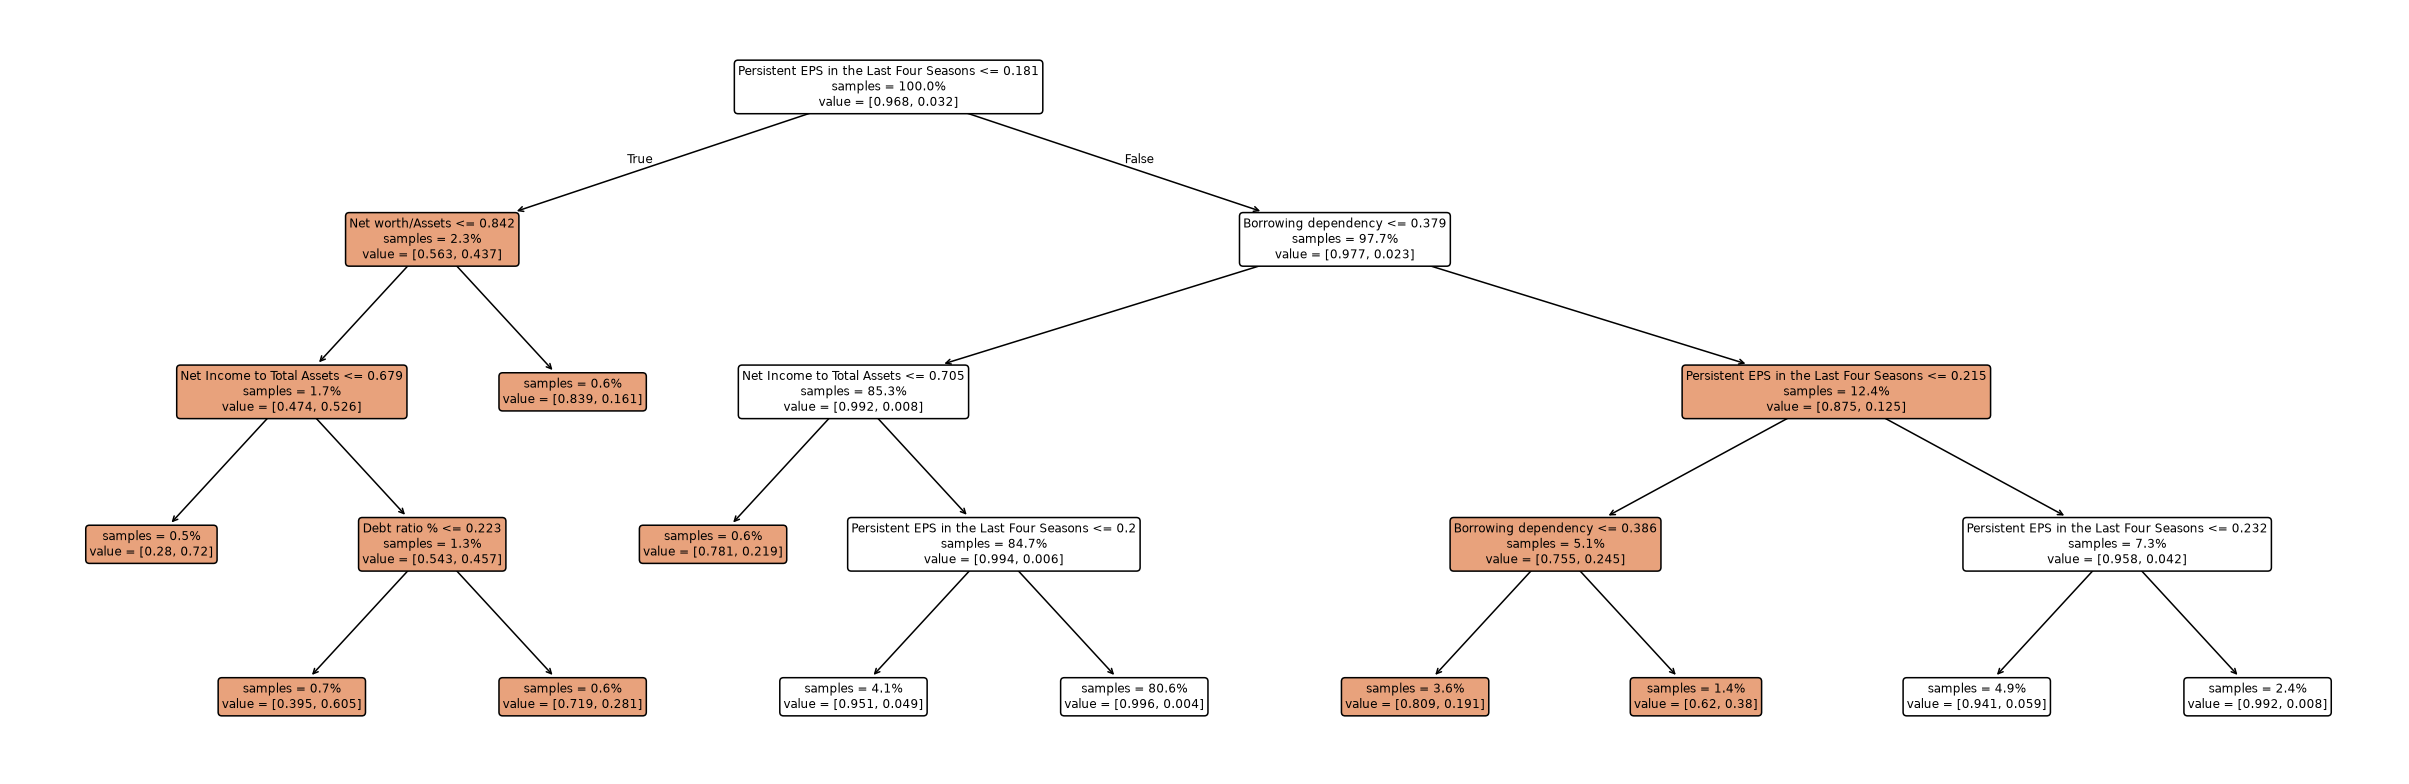

Variables selected: ['ROA(B) before interest and depreciation after tax', 'Persistent EPS in the Last Four Seasons', 'Debt ratio %', 'Net worth/Assets', 'Borrowing dependency', 'Net Income to Total Assets']


In [7]:
final_columns = select_variables(X_dev, y_dev, OPTIONS[best["selection"]])
final_tree = DecisionTreeClassifier(max_depth=int(best["depth"]), min_samples_leaf=int(best["leaf"]),
                                    random_state=SEED).fit(X_dev[final_columns], y_dev)

fig, ax = plt.subplots(figsize=(28, 9))
boxes = plot_tree(final_tree, feature_names=final_columns, proportion=True, impurity=False,
                  rounded=True, fontsize=8, ax=ax)
boxes = [b for b in boxes if b.get_bbox_patch() is not None]     # node boxes, in node order
for box, share in zip(boxes, final_tree.tree_.value[:, 0, 1]):
    box.get_bbox_patch().set_facecolor("#e8a27c" if share >= THRESHOLD else "white")
plt.show()
print("Variables selected:", final_columns)

The selection keeps 6 ratios. The first question, about **Persistent EPS** (earnings per share over the last four quarters), separates most firms: low earnings put a firm into a small, high-risk group. **Borrowing dependency** and the debt-related ratios refine the decision.

## 9. The one and only test
Now we evaluate the frozen model on the 1,364 test firms. We do not change anything afterwards, otherwise the test would become part of the selection (Lecture 2, p. 3).

In [8]:
reference_columns = select_variables(X_dev, y_dev, None)
reference_tree = DecisionTreeClassifier(max_depth=int(best_all["depth"]), min_samples_leaf=int(best_all["leaf"]),
                                        random_state=SEED).fit(X_dev[reference_columns], y_dev)

test_p = {
    "chosen model": final_tree.predict_proba(X_test[final_columns])[:, 1],
    "best without selection": reference_tree.predict_proba(X_test[reference_columns])[:, 1],
    "never flag": np.zeros(len(y_test)),
}
pd.DataFrame({name: score(y_test, p) for name, p in test_p.items()}).T.round(3)

,cost,recall,flags
chosen model,0.149,0.705,104.0
best without selection,0.174,0.750,161.0
never flag,0.323,0.000,0.0


## 10. Results
The table brings everything together: the validation cost (used to **choose** the model) and the test results (the **final, independent assessment**).

In [9]:
def test_counts(p):
    flag, actual = p >= THRESHOLD, y_test.to_numpy() == 1
    return {"bankruptcies caught (of 44)": int((flag & actual).sum()),
            "bankruptcies missed": int((~flag & actual).sum()),
            "false alarms": int((flag & ~actual).sum()),
            "test cost per firm": score(y_test, p)["cost"]}

results_table = pd.DataFrame([test_counts(p) for p in test_p.values()], index=list(test_p))
results_table.insert(0, "validation cost per firm", [best["mean_cost"], best_all["mean_cost"], never_flag])
results_table.insert(0, "ratios available to the tree", [len(final_columns), len(reference_columns), 0])
results_table.round(3)

,ratios available to the tree,validation cost per firm,bankruptcies caught (of 44),bankruptcies missed,false alarms,test cost per firm
chosen model,6,0.158,31,13,73,0.149
best without selection,92,0.166,33,11,128,0.174
never flag,0,0.323,0,44,0,0.323


**Results in four sentences.**
1. **Chosen model:** L1 selection with $C = 0.01$ (6 ratios), then a tree of depth 4 with at least 25 firms per leaf, flagging firms with an estimated bankruptcy probability of at least 0.091.
2. **It halves the cost of doing nothing:** 0.149 per firm on the test set, against 0.323 for never flagging.
3. **It catches 31 of the 44 bankruptcies** in the test set, at the price of 73 false alarms (104 firms flagged out of 1,364).
4. **Selection simplifies without losing performance:** with 6 instead of 92 ratios, it is as good as or better than the best tree on all ratios (0.149 vs 0.174 on the test set; 0.158 vs 0.166 on validation, a difference within the fold-to-fold spread).

The test cost (0.149) is close to the validation cost (0.158), so the model choice was not overly optimistic.

## 11. Conclusion and limitations
**Recommendation.** Use this tree as a **first screening tool**: it tells the analyst which firms to review first. It supports the review; it does not replace it.

**Limitations.**
- Only 44 bankruptcies in the test set: one more missed bankruptcy changes the cost by $10/1364 \approx 0.007$.
- The cost ratio 10 : 1 is an assumption. A different ratio changes the threshold and possibly the chosen model.
- Selection does not clearly beat the tree on all ratios; its benefit is simplicity.
- No dates or company IDs: we cannot test the model on later years.

> **LLM disclosure.** An LLM helped write this notebook. The full prompts and answers belong in the report appendix.